# Assignment 10: Exploratory Data Analysis

Dataset: `hotel_bookings.csv`, 20,000 bookings from two hotels, 24 columns.

The data is a sample of the hotel booking demand dataset published by Antonio,
de Almeida and Nunes (2019) in Data in Brief 22:41-49.

Work through the questions in order. Several of them depend on decisions you
made in an earlier question, so the order matters.

For each question, write your code and then write your conclusions in a
markdown cell below it.

Keep `hotel_bookings.csv` in the same folder as this notebook.

Each question comes with a skeleton. The steps are laid out in order, the
variable names are chosen for you, and the line that prints or shows the
result is already written. Wherever you see `...` you supply the expression,
and the comment beside it tells you what is wanted. Delete the hint once it
works.

The skeletons cover the mechanics only. The cell below sets everything up and gives you a set of helper functions for
the repetitive plotting. Read them, then use them.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')

df = pd.read_csv('hotel_bookings.csv')
print('rows, columns:', df.shape)
df.head()

rows, columns: (20000, 24)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,deposit_type,agent,company,customer_type,adr,total_of_special_requests,reserved_room_type,assigned_room_type,booking_changes,reservation_status_date
0,Resort Hotel,0,203,2016,December,2,5,2,0.0,0,BB,GBR,Direct,Direct,No Deposit,250.0,NaN,Transient,66.8,0,F,F,4,2016-12-09
1,City Hotel,1,82,2015,July,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,No Deposit,9.0,NaN,Transient,76.5,0,A,A,0,2015-07-16
2,City Hotel,0,25,2016,December,0,3,3,0.0,0,BB,BRA,Offline TA/TO,TA/TO,No Deposit,220.0,NaN,Transient-Party,60.0,1,A,K,2,2016-12-30
3,City Hotel,0,1,2016,March,0,1,1,0.0,0,BB,SWE,Online TA,TA/TO,No Deposit,9.0,NaN,Transient-Party,95.0,0,A,A,0,2016-03-10
4,City Hotel,0,70,2017,April,2,2,2,0.0,0,SC,GBR,Online TA,TA/TO,No Deposit,9.0,NaN,Transient,108.0,0,A,A,0,2017-04-20


In [3]:
# ---------------------------------------------------------------------
# Helper functions. These are given to you so that you spend your time on
# the analysis rather than on repetitive plotting code. Use them freely.
# ---------------------------------------------------------------------

def grid_of_histograms(data, columns, bins=30, kde=True, ncols=3, height=3.2):
    """Draw a histogram (optionally with a KDE curve) for each column."""
    columns = list(columns)
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.2, nrows * height))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        sns.histplot(data[col].dropna(), bins=bins, kde=kde, ax=ax)
        ax.set_title(col, fontsize=10)
        ax.set_xlabel('')
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


def grid_of_boxplots(data, columns, ncols=4, height=3.0):
    """Draw an individual box plot for each column, each on its own scale."""
    columns = list(columns)
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.2, nrows * height))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        sns.boxplot(y=data[col].dropna(), ax=ax)
        ax.set_title(col, fontsize=10)
        ax.set_ylabel('')
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


def common_scale_boxplot(data, columns, title, figsize=(12, 5)):
    """Draw every column as a box plot on one shared vertical scale."""
    plt.figure(figsize=figsize)
    sns.boxplot(data=data[list(columns)])
    plt.title(title)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


def correlation_heatmap(data, columns, title, figsize=(9, 7)):
    """Draw a heatmap of the pairwise correlation coefficients."""
    corr = data[list(columns)].corr()
    plt.figure(figsize=figsize)
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
                vmin=-1, vmax=1, square=False, cbar_kws={'shrink': 0.8})
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return corr


def describe_categorical(data, columns):
    """A descriptive statistics table for categorical columns."""
    rows = []
    for col in columns:
        counts = data[col].value_counts(dropna=False)
        rows.append({
            'column': col,
            'distinct values': data[col].nunique(dropna=True),
            'missing': int(data[col].isnull().sum()),
            'most frequent': counts.index[0],
            'its count': int(counts.iloc[0]),
            'rarest': counts.index[-1],
            'its count ': int(counts.iloc[-1]),
        })
    return pd.DataFrame(rows).set_index('column')

## Q1. Data understanding and integrity checks

Carry out the following checks on the raw data, before changing anything.

a. How many rows and how many columns are present?

b. How many columns contain missing data, and how many rows contain at least
one missing value? Look at the second number carefully and say what it would
mean to simply drop every row that has a missing value anywhere.

c. How many exact duplicate rows are present? Decide whether they should be
removed, and justify your decision. A purely mathematical answer is not
enough here, say what duplicates would mean for hotel bookings specifically.

In [4]:
# Q1 a. How many rows and how many columns?
shape = df.shape                   
print('rows and columns:', shape)


# Q1 b. Which columns have missing data, and how many rows are affected?
missing_per_column = df.isnull().sum()
missing_per_column = missing_per_column[missing_per_column > 0]
print('columns with gaps:')
print(missing_per_column)

rows_with_a_gap = df.isnull().any(axis=1).sum()  
print()
print('rows with at least one missing value: %s of %s'
      % (rows_with_a_gap, len(df)))
print('rows that would survive dropna(): ', len(df.dropna()))
# Look at that last number before you decide anything.


# Q1 c. How many exact duplicate rows?
n_duplicates = df.duplicated().sum()             
print()
print('exact duplicate rows: %s (%.2f%%)' % (n_duplicates,
                                             100 * n_duplicates / len(df)))

# Look at a few of them before deciding. Are they plausible as real bookings?
print()
print(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(4))

# It also helps to ask what KIND of booking gets duplicated. Compare the
# duplicated rows against the file as a whole on a column or two, for example
# market_segment or deposit_type, and on mean lead_time.
duplicated_rows = df[df.duplicated(keep=False)]
print()
print('market_segment, whole file:')
print(df['market_segment'].value_counts(normalize=False).head(3))                     
print('market_segment, duplicates only:')
print(duplicated_rows["market_segment"].value_counts(normalize=False).head(3))

rows and columns: (20000, 24)
columns with gaps:
country      103
agent       2775
company    18845
dtype: int64

rows with at least one missing value: 19970 of 20000
rows that would survive dropna():  30

exact duplicate rows: 3260 (16.30%)

            hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  stays_in_weekend_nights  stays_in_week_nights  adults  children  babies meal  \
5914   City Hotel            0          0               2015             August                        0                     2       2       0.0       0   BB   
17378  City Hotel            0          0               2015             August                        0                     2       2       0.0       0   BB   
12770  City Hotel            0          0               2016            January                        0                     1       1       0.0       0   SC   
13950  City Hotel            0          0               2016            January                        0         

**Your conclusions for Q1:**

a. How many rows and how many columns are present?
Rows: 20000
Columns: 24

b. How many columns contain missing data, and how many rows contain at least one missing
value? Look at the second number carefully and say what it would mean to simply drop every
row that has a missing value anywhere.
3 columns contain missing data : country, agent, company
Rows with atleast one value missing : 19970

It would only leave 30 rows out of the 20000 which would not be enough data for any type of training

c. How many exact duplicate rows are present? Decide whether they should be removed, and
justify your decision. A purely mathematical answer is not enough here, say what duplicates
would mean for hotel bookings specifically
Number of duplicate rows: 3260
It would be ideal to remove duplicates but we are unsure if they are truly duplicates or if they are instances of similar booking. In the displayed example, it could be 2 couples travelling on the same day with similar bookings, etc. This is especially true because there is no way to identify the customer.


### The level of measurement of each column

Deciding the level of measurement is a judgement call, so the table is given to you here. Run the cell to see it, and
refer back to it whenever a question asks which statistic or which plot is
appropriate. Please be careful of the `agent` column: it holds
numbers, but they are labels for travel agents, so averaging them is
meaningless.

In [5]:
# Level of measurement for each column
levels = {
    'hotel':                     ('Nominal',  'Two categories, no ordering'),
    'is_canceled':               ('Nominal',  'Binary flag, 0 or 1'),
    'lead_time':                 ('Ratio',    'Days, a true zero exists'),
    'arrival_date_year':         ('Interval', 'Year, ordered, no meaningful zero'),
    'arrival_date_month':        ('Ordinal',  'Months have an order but no true zero'),
    'stays_in_weekend_nights':   ('Ratio',    'Count of nights, true zero'),
    'stays_in_week_nights':      ('Ratio',    'Count of nights, true zero'),
    'adults':                    ('Ratio',    'Count of people, true zero'),
    'children':                  ('Ratio',    'Count of people, true zero'),
    'babies':                    ('Ratio',    'Count of people, true zero'),
    'meal':                      ('Nominal',  'Meal plan code'),
    'country':                   ('Nominal',  'Country of origin'),
    'market_segment':            ('Nominal',  'Booking channel grouping'),
    'distribution_channel':      ('Nominal',  'Distribution route'),
    'deposit_type':              ('Nominal',  'Deposit arrangement'),
    'agent':                     ('Nominal',  'Travel agent id, a label not a quantity'),
    'company':                   ('Nominal',  'Company id, a label not a quantity'),
    'customer_type':             ('Nominal',  'Booking type'),
    'adr':                       ('Ratio',    'Average daily rate in currency, true zero'),
    'total_of_special_requests': ('Ratio',    'Count of requests, true zero'),
    'reserved_room_type':        ('Nominal',  'Room class code the guest booked'),
    'assigned_room_type':        ('Nominal',  'Room class code actually given'),
    'booking_changes':           ('Ratio',    'Count of amendments, true zero'),
    'reservation_status_date':   ('Interval', 'A date, differences are meaningful'),
}

tools = {
    'Nominal':  'mode, frequency table; bar chart',
    'Ordinal':  'mode, median, frequency table; bar chart',
    'Interval': 'mean, standard deviation, range; histogram, line plot',
    'Ratio':    'mean, median, std, all ratios; histogram, box plot, scatter',
}

level_table = pd.DataFrame(
    [{'column': c, 'level': lv, 'why': why, 'appropriate tools': tools[lv]}
     for c, (lv, why) in levels.items()]
).set_index('column')
level_table

,level,why,appropriate tools
column,,,
hotel,Nominal,"Two categories, no ordering","mode, frequency table; bar chart"
is_canceled,Nominal,"Binary flag, 0 or 1","mode, frequency table; bar chart"
lead_time,Ratio,"Days, a true zero exists","mean, median, std, all ratios; histogram, box ..."
arrival_date_year,Interval,"Year, ordered, no meaningful zero","mean, standard deviation, range; histogram, li..."
arrival_date_month,Ordinal,Months have an order but no true zero,"mode, median, frequency table; bar chart"
stays_in_weekend_nights,Ratio,"Count of nights, true zero","mean, median, std, all ratios; histogram, box ..."
stays_in_week_nights,Ratio,"Count of nights, true zero","mean, median, std, all ratios; histogram, box ..."
adults,Ratio,"Count of people, true zero","mean, median, std, all ratios; histogram, box ..."
children,Ratio,"Count of people, true zero","mean, median, std, all ratios; histogram, box ..."


## Q2. Descriptive statistics, and class balance

a. Produce descriptive statistics for every column, choosing the statistics
that suit the level of measurement given in the table above. Organise the numerical
columns in one table and the categorical columns in another, so the two can be
read side by side. State your initial conclusions.

b. Look at the balance of the categorical columns. For `deposit_type`,
`distribution_channel`, `customer_type` and `market_segment`, tabulate how many
rows fall in each class. Identify the rarest classes.

If one of these columns were used as the target of a classification model,
explain why accuracy would give a misleading picture, and what the F1 score
would add. You do not need to build the model, the argument is what matters.

In [ ]:
`# Q2 a. Descriptive statistics for the numerical columns
numeric_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
                'adults', 'children', 'babies', 'adr',
                'total_of_special_requests', 'booking_changes']
numeric_summary = df[numeric_cols].describe().T.round(2)       
display(numeric_summary)


# Q2 a. Descriptive statistics for the categorical columns
# describe_categorical is provided for exactly this.
categorical_cols = ['hotel', 'arrival_date_month', 'meal', 'country',
                    'market_segment', 'distribution_channel', 'deposit_type',
                    'customer_type', 'reserved_room_type', 'assigned_room_type',
                    'agent', 'company']
display(describe_categorical(df, categorical_cols))      

# One value in the adr column should make you stop and look. Find how many
# bookings have a rate of exactly zero, and check what kind of bookings they
# are before you explain them away.
zero_rate = df['adr'] == 0
print('bookings with adr exactly 0:', zero_rate.sum())
print(df.loc[zero_rate,'market_segment'].value_counts())


# Q2 b. Class balance
for col in ['deposit_type', 'distribution_channel', 'customer_type',
            'market_segment']:
    counts = df[col].value_counts()              
    share = (100 * counts / counts.sum()).round(2)
    print('--- %s ---' % col)
    print(pd.DataFrame({'count': counts, 'percent': share}).to_string())
    print()

# Now the argument. Pick the most imbalanced column above. If a classifier
# always predicted its commonest class, what accuracy would it score? Work the
# number out rather than guessing it, then write the F1 argument in markdown.
majority_share = max(
    df[col].value_counts(normalize=True).max() * 100
    for col in ['deposit_type', 'distribution_channel',
                'customer_type', 'market_segment']
)
print('always predicting the commonest class scores %.1f%% accuracy'
      % majority_share)

,count,mean,std,min,25%,50%,75%,max
lead_time,20000.0,104.68,106.94,0.0,19.00,70.0,161.0,629.0
stays_in_weekend_nights,20000.0,0.93,0.99,0.0,0.00,1.0,2.0,19.0
stays_in_week_nights,20000.0,2.50,1.90,0.0,1.00,2.0,3.0,50.0
adults,20000.0,1.86,0.63,0.0,2.00,2.0,2.0,55.0
children,20000.0,0.10,0.40,0.0,0.00,0.0,0.0,3.0
babies,20000.0,0.01,0.11,0.0,0.00,0.0,0.0,9.0
adr,20000.0,101.54,47.75,0.0,68.45,94.5,125.4,451.5
total_of_special_requests,20000.0,0.57,0.80,0.0,0.00,0.0,1.0,5.0
booking_changes,20000.0,0.22,0.65,0.0,0.00,0.0,0.0,17.0


,distinct values,missing,most frequent,its count,rarest,its count
column,,,,,,
hotel,2,0,City Hotel,13203,Resort Hotel,6797
arrival_date_month,12,0,August,2300,January,1005
meal,5,0,BB,15487,FB,136
country,120,103,PRT,8238,CMR,1
market_segment,7,0,Online TA,9343,Aviation,38
distribution_channel,5,0,TA/TO,16321,Undefined,1
deposit_type,3,0,No Deposit,17421,Refundable,25
customer_type,4,0,Transient,15066,Group,90
reserved_room_type,9,0,A,14514,P,2


bookings with adr exactly 0: 293
market_segment
Complementary    115
Online TA         48
Offline TA/TO     47
Direct            37
Groups            35
Corporate         11
Name: count, dtype: int64
--- deposit_type ---
              count  percent
deposit_type                
No Deposit    17421    87.10
Non Refund     2554    12.77
Refundable       25     0.12

--- distribution_channel ---
                      count  percent
distribution_channel                
TA/TO                 16321    81.60
Direct                 2495    12.48
Corporate              1148     5.74
GDS                      35     0.18
Undefined                 1     0.00

--- customer_type ---
                 count  percent
customer_type                  
Transient        15066    75.33
Transient-Party   4150    20.75
Contract           694     3.47
Group               90     0.45

--- market_segment ---
                count  percent
market_segment                
Online TA        9343    46.72
Offline TA/TO

**Your conclusions for Q2:**

**a.**

Initial conclusions:
Numerical columns:
1) Lead time: 104 days is the average but the median is 70 days which suggests te data is right skewed.
2) Usually bookings have 0.93 nights on weekends and 2.5 nights on weeekdays which makes sense considring the fact that the number of weekend nights is less as well as the ppl who would book for long periods within the weekdays or longer overall would still mean shorter weekend night values.
3) On an average there are about 2 adults per booking but it is weird to see the max being 55, may be it is because of a group outing. Same goes for max number of babies being 9
4) On an average there are very low number of special requests, same for booking changes but the high number of 17 booking changes needs to be investigated.

Categorical columns:
1) Most bookings prefer City hotel.
2) Most number of bookings are in the moth of August and least in January.
3) The country value has 120 distinct values suggesting visitors from varied nationalities.
4) Most number of bookings dont have a deposit.
5) The number of group bookings is very low.
6) There are 2775 rows missing the values of agent column it might be due to various reasons which needs to be checked.
7) Company data is missing for 18845 rows which makes it unusable fo rany kind of analysis


**b.**
### Q2. Initial observations and class imbalance

There are 293 bookings with an ADR of exactly zero. The Complementary market segment accounts for the largest number of 115 bookings, suggesting that some may represent complimentary hotel stays.

The categorical columns show considerable class imbalance. In `deposit_type`, 87.10% of bookings belong to the No Deposit category, while only 25 bookings belong to the Refundable category. Similarly, TA/TO dominates `distribution_channel` with 81.60%, Transient dominates `customer_type` with 75.33%, and Online TA is the largest `market_segment` with 46.72%.

Among these four columns, `deposit_type` is the most imbalanced. A classifier that always predicts No Deposit would achieve approximately 87.1% accuracy without learning meaningful patterns.

This demonstrates why accuracy alone can be misleading for imbalanced classification problems. The F1 score provides additional information by considering both precision and recall. Macro F1 is particularly useful for multiclass classification because it gives equal importance to every class, including minority classes.



## Q3. Is this time-series data?

The file offers two ways to place a booking in time: the arrival date, held
as `arrival_date_year` and `arrival_date_month`, and `reservation_status_date`.

Before plotting anything, work out what each one actually records, and decide
which belongs on the horizontal axis of a seasonality plot. They are not
interchangeable.

Then decide whether this is time-series data. Plot the number of bookings over
time and plot `adr` against time. Do you see any trend, any seasonality, or
neither?

State what the plots let you conclude, and what they do not.

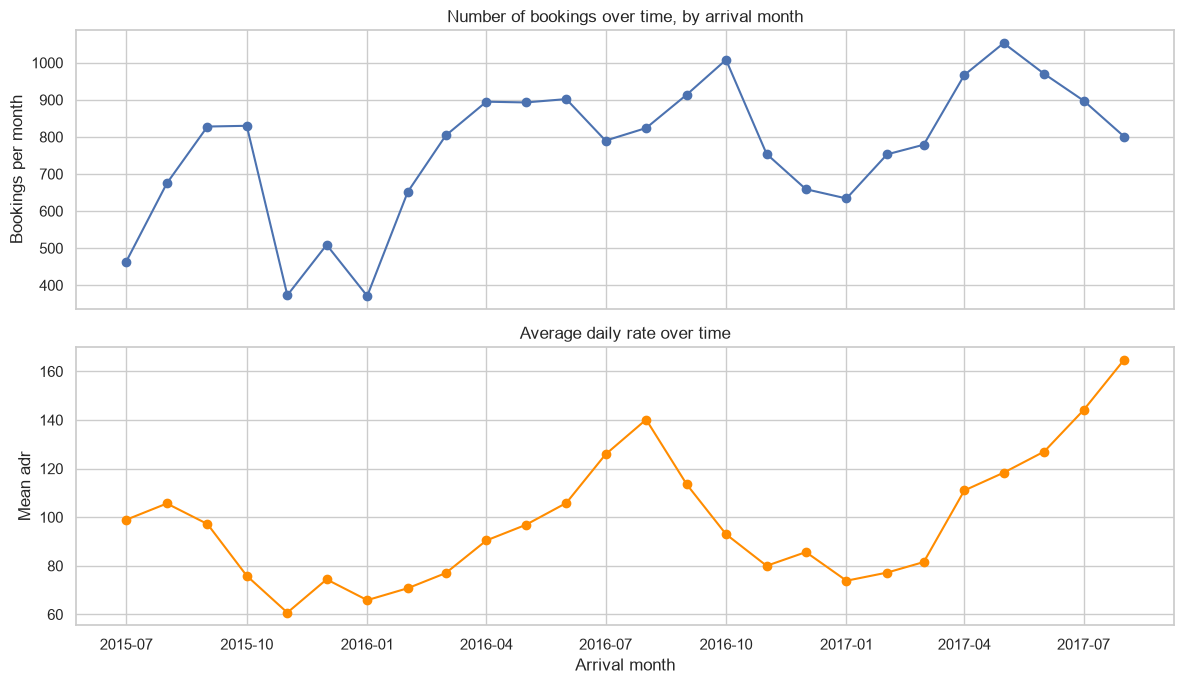

Bookings per arrival year:
arrival_date_year
2015    3679
2016    9466
2017    6855
Name: count, dtype: int64

Mean adr per arrival year:
arrival_date_year
2015     87.31
2016     97.67
2017    114.51
Name: adr, dtype: float64

Highest monthly mean adr in each year:
arrival_period
2015    105.6
2016    140.2
2017    164.8
Name: mean_adr, dtype: float64

Lowest monthly mean adr in each year:
arrival_period
2015    60.7
2016    65.9
2017    73.9
Name: mean_adr, dtype: float64

status month differs from arrival month in 36.4% of bookings


In [7]:
# Q3. Is this time-series data?
# First decide which date belongs on the axis. reservation_status_date records
# when a booking reached its final status, a check-out or a cancellation, so
# it is not when the stay happened. Place the bookings by ARRIVAL month.
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
          'August', 'September', 'October', 'November', 'December']
month_number = {m: i + 1 for i, m in enumerate(MONTHS)}

work = df.copy()
work['reservation_status_date'] = pd.to_datetime( 
    work['reservation_status_date'],
    format='%Y-%m-%d'
)  
work['arrival_period'] = pd.PeriodIndex(
    work['arrival_date_year'].astype(str) + '-'
    + work['arrival_date_month'].map(month_number).map('{:02d}'.format),
    freq='M')

# Group by arrival month: how many bookings, and what mean adr?
per_month = work.groupby('arrival_period').agg( bookings=('adr','size'),mean_adr=('adr','mean'))
per_month.index = per_month.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(per_month.index, per_month['bookings'], marker='o', lw=1.5)
axes[0].set_ylabel('Bookings per month')
axes[0].set_title('Number of bookings over time, by arrival month')
axes[1].plot(per_month.index, per_month['mean_adr'], marker='o', lw=1.5,
             color='darkorange')
axes[1].set_ylabel('Mean adr')
axes[1].set_xlabel('Arrival month')
axes[1].set_title('Average daily rate over time')
plt.tight_layout()
plt.show()

# Numbers to put behind what you see in the lower panel.
print('Bookings per arrival year:')
print(work['arrival_date_year'].value_counts().sort_index())                      
print()
print('Mean adr per arrival year:')
print(work.groupby('arrival_date_year')['adr'].mean().round(2))                      

# There are TWO patterns in the lower panel, not one. Find the highest monthly
# mean in each year, and then the lowest, before you write your answer.
print()
print('Highest monthly mean adr in each year:')
print(per_month.groupby(per_month.index.year)['mean_adr'].max().round(1))
print()
print('Lowest monthly mean adr in each year:')
print(per_month.groupby(per_month.index.year)['mean_adr'].min().round(1))                      

# Finally, check how much the choice of date column mattered. How often do
# the status month and the arrival month disagree?
same_month = (work['reservation_status_date'].dt.to_period('M')
              == work['arrival_period'])
print()
print('status month differs from arrival month in %.1f%% of bookings'
      % (100 * (~same_month).mean()))

**Your conclusions for Q3:**

It is time series data.
We can see that the highest number of bookings is during the 8th month, both the number of bookings ad adr seem to increase owards and decrease after this month. 2016 saw a huge uptick in the number of bookings but the trend didnt continue to 2017. but the adr increased suggesting a significant increase in revenue year on year.

## Q4. Initial strategy for the missing values

Based on everything so far, set out your initial plan for each of the three
columns that contain missing values. Do not implement anything yet, Q10 is
where the decisions get carried out.

For each column say what you propose and why. The right answer is different
for each of the three.

In [9]:
# Q4. A strategy for each column that has gaps. Do NOT change anything yet.
# This question is the plan. Q10 is where you carry it out.

gap_report = pd.DataFrame({
    'missing': df.isnull().sum(),
    'percent': (100 * df.isnull().mean()).round(2),
    'dtype': df.dtypes.astype(str),
})
gap_report = gap_report[gap_report['missing'] > 0]
print(gap_report.to_string())

# For each of the three columns, look at enough of it to justify a decision.
for col in gap_report.index:
    print()
    print('--- %s ---' % col)
    print('distinct values present:', df[col].nunique())   
    print(df[col].value_counts(dropna=True).head(3).to_string())

# Then write your plan in the markdown cell below: for each column, what you
# will do and why. Dropping, filling with a label, and filling with a
# statistic are all defensible for different columns. Say which and why.
# One of these three columns should not be imputed at all. Decide which.

         missing  percent    dtype
country      103     0.52      str
agent       2775    13.88  float64
company    18845    94.22  float64

--- country ---
distinct values present: 120
country
PRT    8238
GBR    2061
FRA    1696

--- agent ---
distinct values present: 253
agent
9.0      5256
240.0    2336
1.0      1194

--- company ---
distinct values present: 191
company
40.0     156
223.0    134
67.0      52


**Your conclusions for Q4:**

There are mainly 3 columns with missing data:
1) Country: Because it has the least number of missing data points, it would make sense to either remove the rows with missing data or just keep it with Unknown label or something like that.
2) Agent: The amount of missing data is higher than country column but it is not the worst. Since we dont know the agent, imputing the value with the most common or any other value would skew the data instead keeping it as NA or some other variable would be better.
3) Company: Amost the entire dataset is missing this dats so i am deciding not to impute it and remove it entirely.

## Q5. A closer look at the `agent` column

In Q4 you proposed a treatment for `agent`. Now test it.

Analyse the column with suitable visualisations. How many distinct agents are
there, and how concentrated is the business among them?

Then examine what else is true of the rows where `agent` is missing. In
particular, cross-tabulate the missing rows against `distribution_channel`.
Does the pattern support the idea that a missing agent means no agent was
involved, or does it look like data was simply lost?

Say what you will do and why.

distinct agent ids: 253
bookings with no agent recorded: 2775

busiest agents:
agent
9.0      5256
240.0    2336
1.0      1194
14.0      621
7.0       603
6.0       532
250.0     513
241.0     271
8.0       263
28.0      261
3.0       241
37.0      220
19.0      190
40.0      184
314.0     147


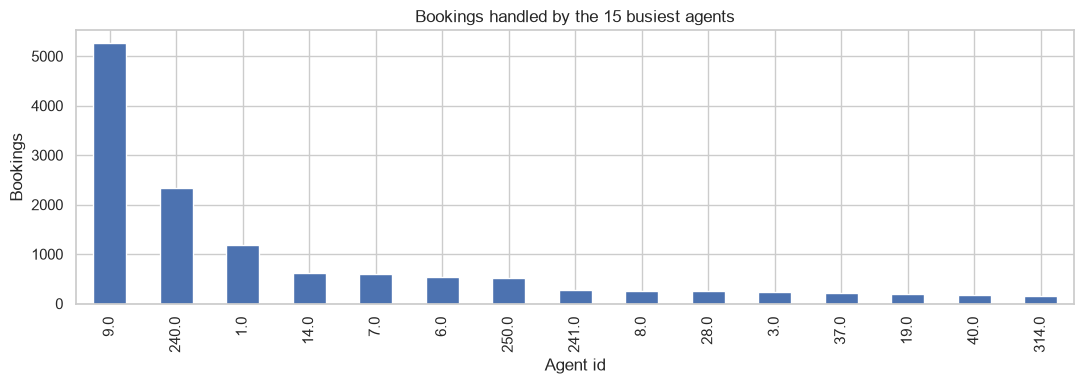

                      agent recorded  agent missing
distribution_channel                               
Corporate                        194            954
Direct                          1218           1277
GDS                               35              0
TA/TO                          15778            543
Undefined                          0              1

percentage of each channel with no agent:
distribution_channel
Corporate     83.10
Direct        51.18
GDS            0.00
TA/TO          3.33
Undefined    100.00
dtype: float64


In [8]:
# Q5. Does a missing agent mean lost data, or something else?

# How many agents are there, and how concentrated is the business?
print('distinct agent ids:',  df['agent'].nunique())        
print('bookings with no agent recorded:',  df['agent'].isnull().sum())  

top_agents = df['agent'].value_counts().head(15)              
print()
print('busiest agents:')
print(top_agents.to_string())

plt.figure(figsize=(11, 4))
top_agents.plot(kind='bar')
plt.title('Bookings handled by the 15 busiest agents')
plt.xlabel('Agent id')
plt.ylabel('Bookings')
plt.tight_layout()
plt.show()


# Q5. Now the key step. Cross-tabulate the rows with a missing agent against
# distribution_channel. Read the result as percentages, not raw counts,
# otherwise the big channel hides the pattern.
missing_agent = df['agent'].isnull()
crosstab = pd.crosstab(df['distribution_channel'], missing_agent)
crosstab.columns = ['agent recorded', 'agent missing']
print(crosstab.to_string())

print()
print('percentage of each channel with no agent:')
print((100 * crosstab['agent missing'] / crosstab.sum(axis=1)).round(2))          
# Compare the channels that sell direct against the ones that go through a
# travel agent. Does the gap look like lost data?

**Your conclusions for Q5:**

There are totally 253 agents of which the top 15 handled 12832 bookings of the total 20000 bookings.

I feel like for corporate bookings with the huge number of missing agent data it might be caused due to the process. The rest of the data might actually have agent data missing.


## Q6. Histograms and KDE plots

Create a histogram with a KDE curve for each numerical column and analyse
what you see.

Find out what a KDE plot represents and explain it in one or two sentences. Say
what it adds over the histogram alone, and what it can mislead you about.

Which columns are skewed? Which are close to symmetric? Which carry almost no
information at all?

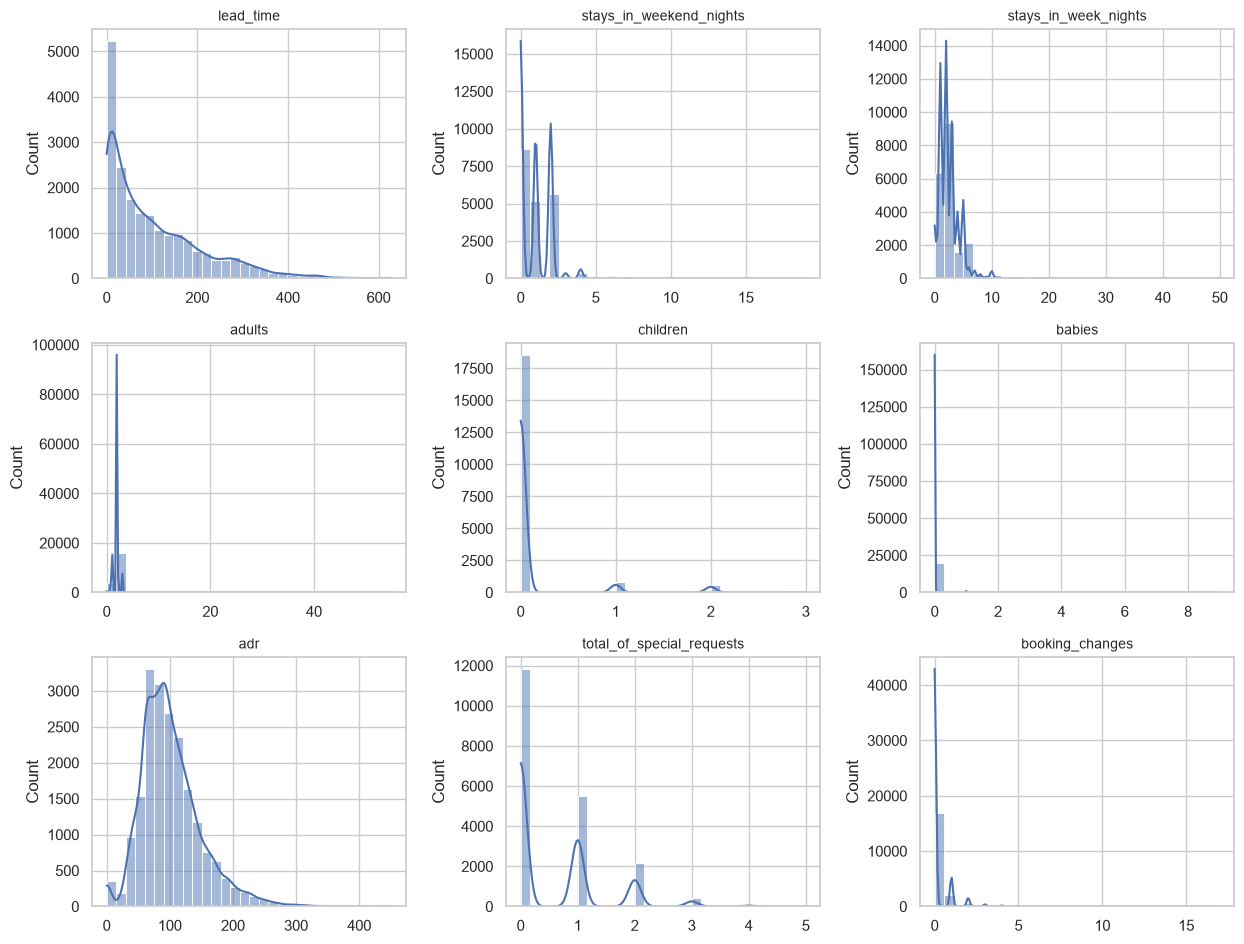

                           skewness  percent zero  most common value
lead_time                      1.33          5.22                0.0
stays_in_weekend_nights        1.40         43.13                0.0
stays_in_week_nights           3.08          6.28                2.0
adults                        31.27          0.34                2.0
children                       4.03         92.78                0.0
babies                        35.73         99.30                0.0
adr                            1.05          1.46               62.0
total_of_special_requests      1.38         59.22                0.0
booking_changes                5.76         84.86                0.0

adr: 25% = 68.4, median = 94.5, 75% = 125.4, max = 451.5


In [ ]:
# Q6. Histograms with a KDE curve for every numerical column.
numeric_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
                'adults', 'children', 'babies', 'adr',
                'total_of_special_requests', 'booking_changes']
grid_of_histograms(df, numeric_cols, bins=30, kde=True)

# Put numbers behind the shapes rather than eyeballing them.
shape_table = pd.DataFrame({
    'skewness': [df[c].skew() for c in numeric_cols],       
    'percent zero': [100 * (df[c] == 0).mean() for c in numeric_cols],   
    'most common value': [df[c].mode()[0] for c in numeric_cols],
}, index=numeric_cols).round(2)
print(shape_table.to_string())

# adr deserves a second look. Is it as symmetric as it appears?
print()
print('adr: 25%% = %.1f, median = %.1f, 75%% = %.1f, max = %.1f'
      % (df.adr.quantile(.25), df.adr.median(), df.adr.quantile(.75),
         df.adr.max()))

# Then, in markdown: what does a KDE represent, what does it add over the
# histogram, and what can it mislead you about? Two of its weaknesses are
# visible in the figure above. One concerns columns that only take whole
# numbers. The other concerns the vertical axis on adults and babies, so
# compare the height of the tallest bar there against the axis label.

**Your conclusions for Q6:**

KDE plots: A Kernel Density Estimation (KDE) curve is a smooth, continuous line that represents the probability density distribution of a dataset. It is a non-parametric alternative to a histogram, meaning it does not assume your data follows a specific shape like a normal distribution

Histograms can look completely different depending on your choice of bin width and starting edges. A KDE eliminates these arbitrary grid lines, offering a continuous view that is less sensitive to exact boundaries.

If your dataset has a massive empty gap between two clusters, the KDE's smoothing process might fill that gap with a shallow curve. This creates the illusion that data points exist in a zone where there are actually zero real observations.

Almost all columns seem to be skewed towards the right. 
Adr is somewhat symmetric.
Most of the values for children, babies and booking changes seem to be 0 which would explain very less about the trends.


## Q7. Individual box plots

Create a box plot for each numerical column, each on its own scale, and
analyse them.

Use the 1.5 times IQR rule to count how many observations each column flags as
an outlier. Then pick one column and argue, from the meaning of the data rather
than the arithmetic, whether those flagged points should actually be removed.

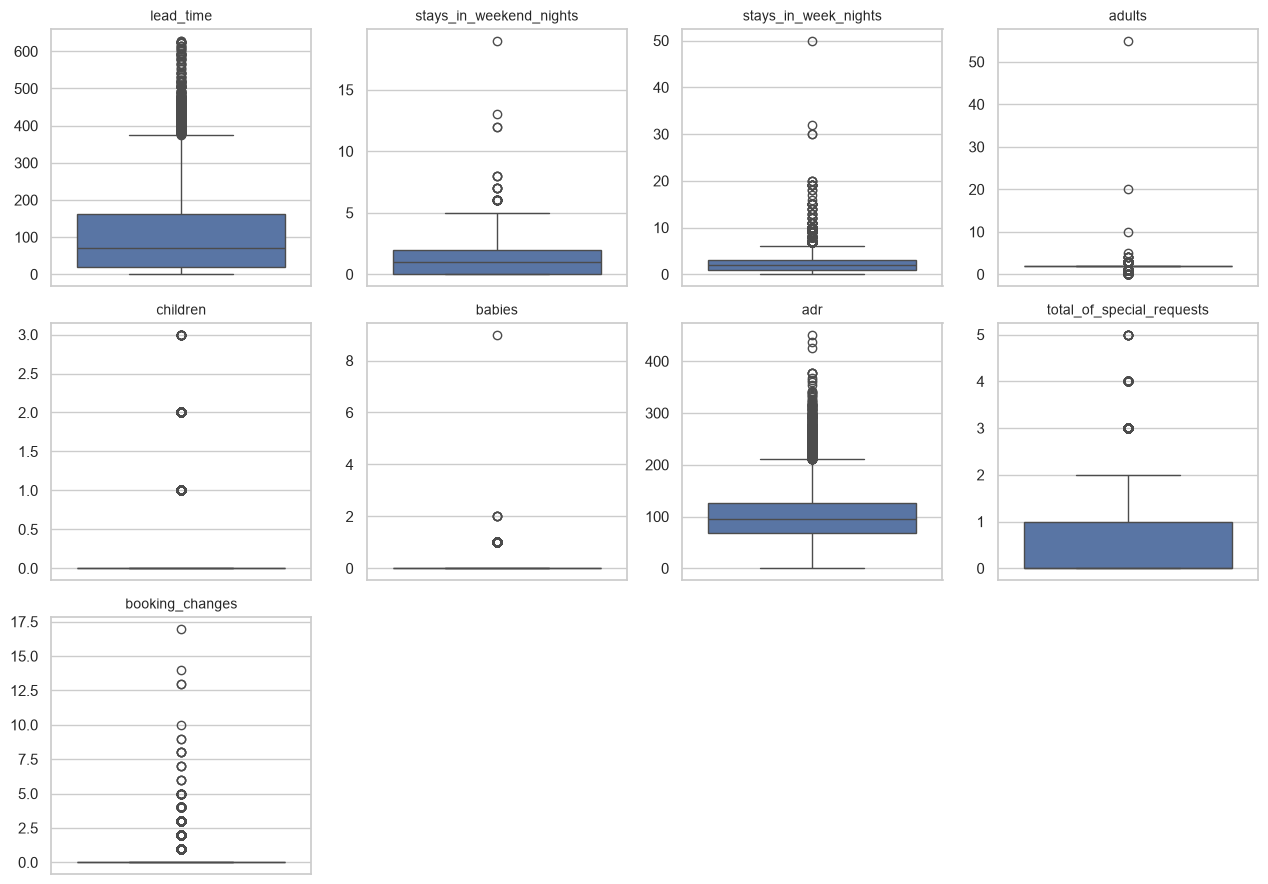

                               Q1     Q2      IQR  lower bound  upper bound  flagged  percent
column                                                                                       
lead_time                  19.000  161.0  142.000    -194.0000     374.0000      501     2.50
stays_in_weekend_nights     0.000    2.0    2.000      -3.0000       5.0000       33     0.16
stays_in_week_nights        1.000    3.0    2.000      -2.0000       6.0000      571     2.86
adults                      2.000    2.0    0.000       2.0000       2.0000     4884    24.42
children                    0.000    0.0    0.000       0.0000       0.0000     1445     7.22
babies                      0.000    0.0    0.000       0.0000       0.0000      141     0.70
adr                        68.445  125.4   56.955     -16.9875     210.8325      618     3.09
total_of_special_requests   0.000    1.0    1.000      -1.5000       2.5000      495     2.48
booking_changes             0.000    0.0    0.000       0.00

In [10]:
# Q7. One box plot per numerical column, each on its own scale.
numeric_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
                'adults', 'children', 'babies', 'adr',
                'total_of_special_requests', 'booking_changes']
grid_of_boxplots(df, numeric_cols)


# Q7. Count what the 1.5 x IQR rule flags in each column.
rows = []
for col in numeric_cols:
    q1 = df[col].quantile(0.25)            
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr         
    upper = q3 + 1.5 * iqr
    flagged = ((df[col] < lower) | (df[col] > upper)).sum()
    rows.append({'column': col, 'Q1': q1, 'Q2': q3, 'IQR': iqr,
                 'lower bound': lower, 'upper bound': upper,
                 'flagged': flagged,
                 'percent': round(100 * flagged / len(df), 2)})
iqr_table = pd.DataFrame(rows).set_index('column')
print(iqr_table.to_string())

# One column in that table has an IQR of zero. Find it and look at its bounds.
# What is the rule actually flagging there, and is that a fault in the data?

# Now check two things the rule arguably SHOULD catch, and see whether it does.
nights = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
print()
print('bookings with zero adults:', (df['adults'] == 0).sum())    
print('bookings with zero nights:', (nights == 0).sum())
# Are these flagged by the table above? Check before you answer.

**Your conclusions for Q7:**

The adults column has the highest number of flagged observations. However, these columns have an IQR of zero, meaning that their middle 50% of observations have identical values. Consequently, even relatively ordinary values are flagged as outliers.

The lead_time column has 501 flagged observations. Its upper boundary is 374 days. Customers may legitimately book hotels more than a year in advance. Hence, removing these values wouldnt be correct.

67 bookings have zero adults and 105 bookings have zero total nights. These records should be investigated as potential data-quality issues.

## Q8. All numerical columns on a common scale

Now draw box plots for all the numerical columns together, on one shared
vertical scale, in a single plot.

What happens, and what does it imply for any model that measures distances or
assigns weights to features?

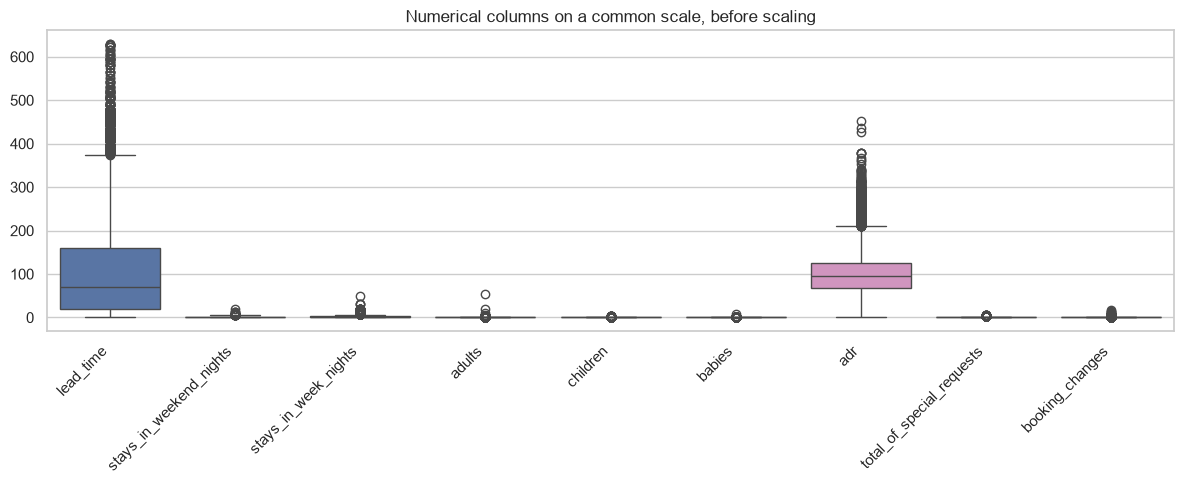

                           min    max    mean     std
lead_time                  0.0  629.0  104.68  106.94
stays_in_weekend_nights    0.0   19.0    0.93    0.99
stays_in_week_nights       0.0   50.0    2.50    1.90
adults                     0.0   55.0    1.86    0.63
children                   0.0    3.0    0.10    0.40
babies                     0.0    9.0    0.01    0.11
adr                        0.0  451.5  101.54   47.75
total_of_special_requests  0.0    5.0    0.57    0.80
booking_changes            0.0   17.0    0.22    0.65


In [11]:
# Q8. All numerical columns on one shared scale, in a single plot.
numeric_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
                'adults', 'children', 'babies', 'adr',
                'total_of_special_requests', 'booking_changes']
common_scale_boxplot(df, numeric_cols,
                     'Numerical columns on a common scale, before scaling')

# The spread of each column explains what you are looking at.
print(df[numeric_cols].agg(['min','max','mean','std']).T.round(2))       

# Then answer in markdown: which columns dominate, why, and what it implies
# for a model that measures distance between rows or penalises coefficients.
# Be precise about plain linear regression, which behaves differently.

**Your conclusions for Q8:**

By having all the values in the same boxplot we see that there is a huge scaling issue. lead_time and adr will end up contributing heavily to any model if they are not scaled appropriately.

## Q9. Relationships between the columns

a. Create pairwise scatter plots for the numerical columns.

b. Create a heatmap of the pairwise correlation coefficients.

c. What do you conclude? Which columns look related to `adr`, which look
unrelated, and are any pairs of features telling you the same thing twice?

Be careful about which columns you include. 

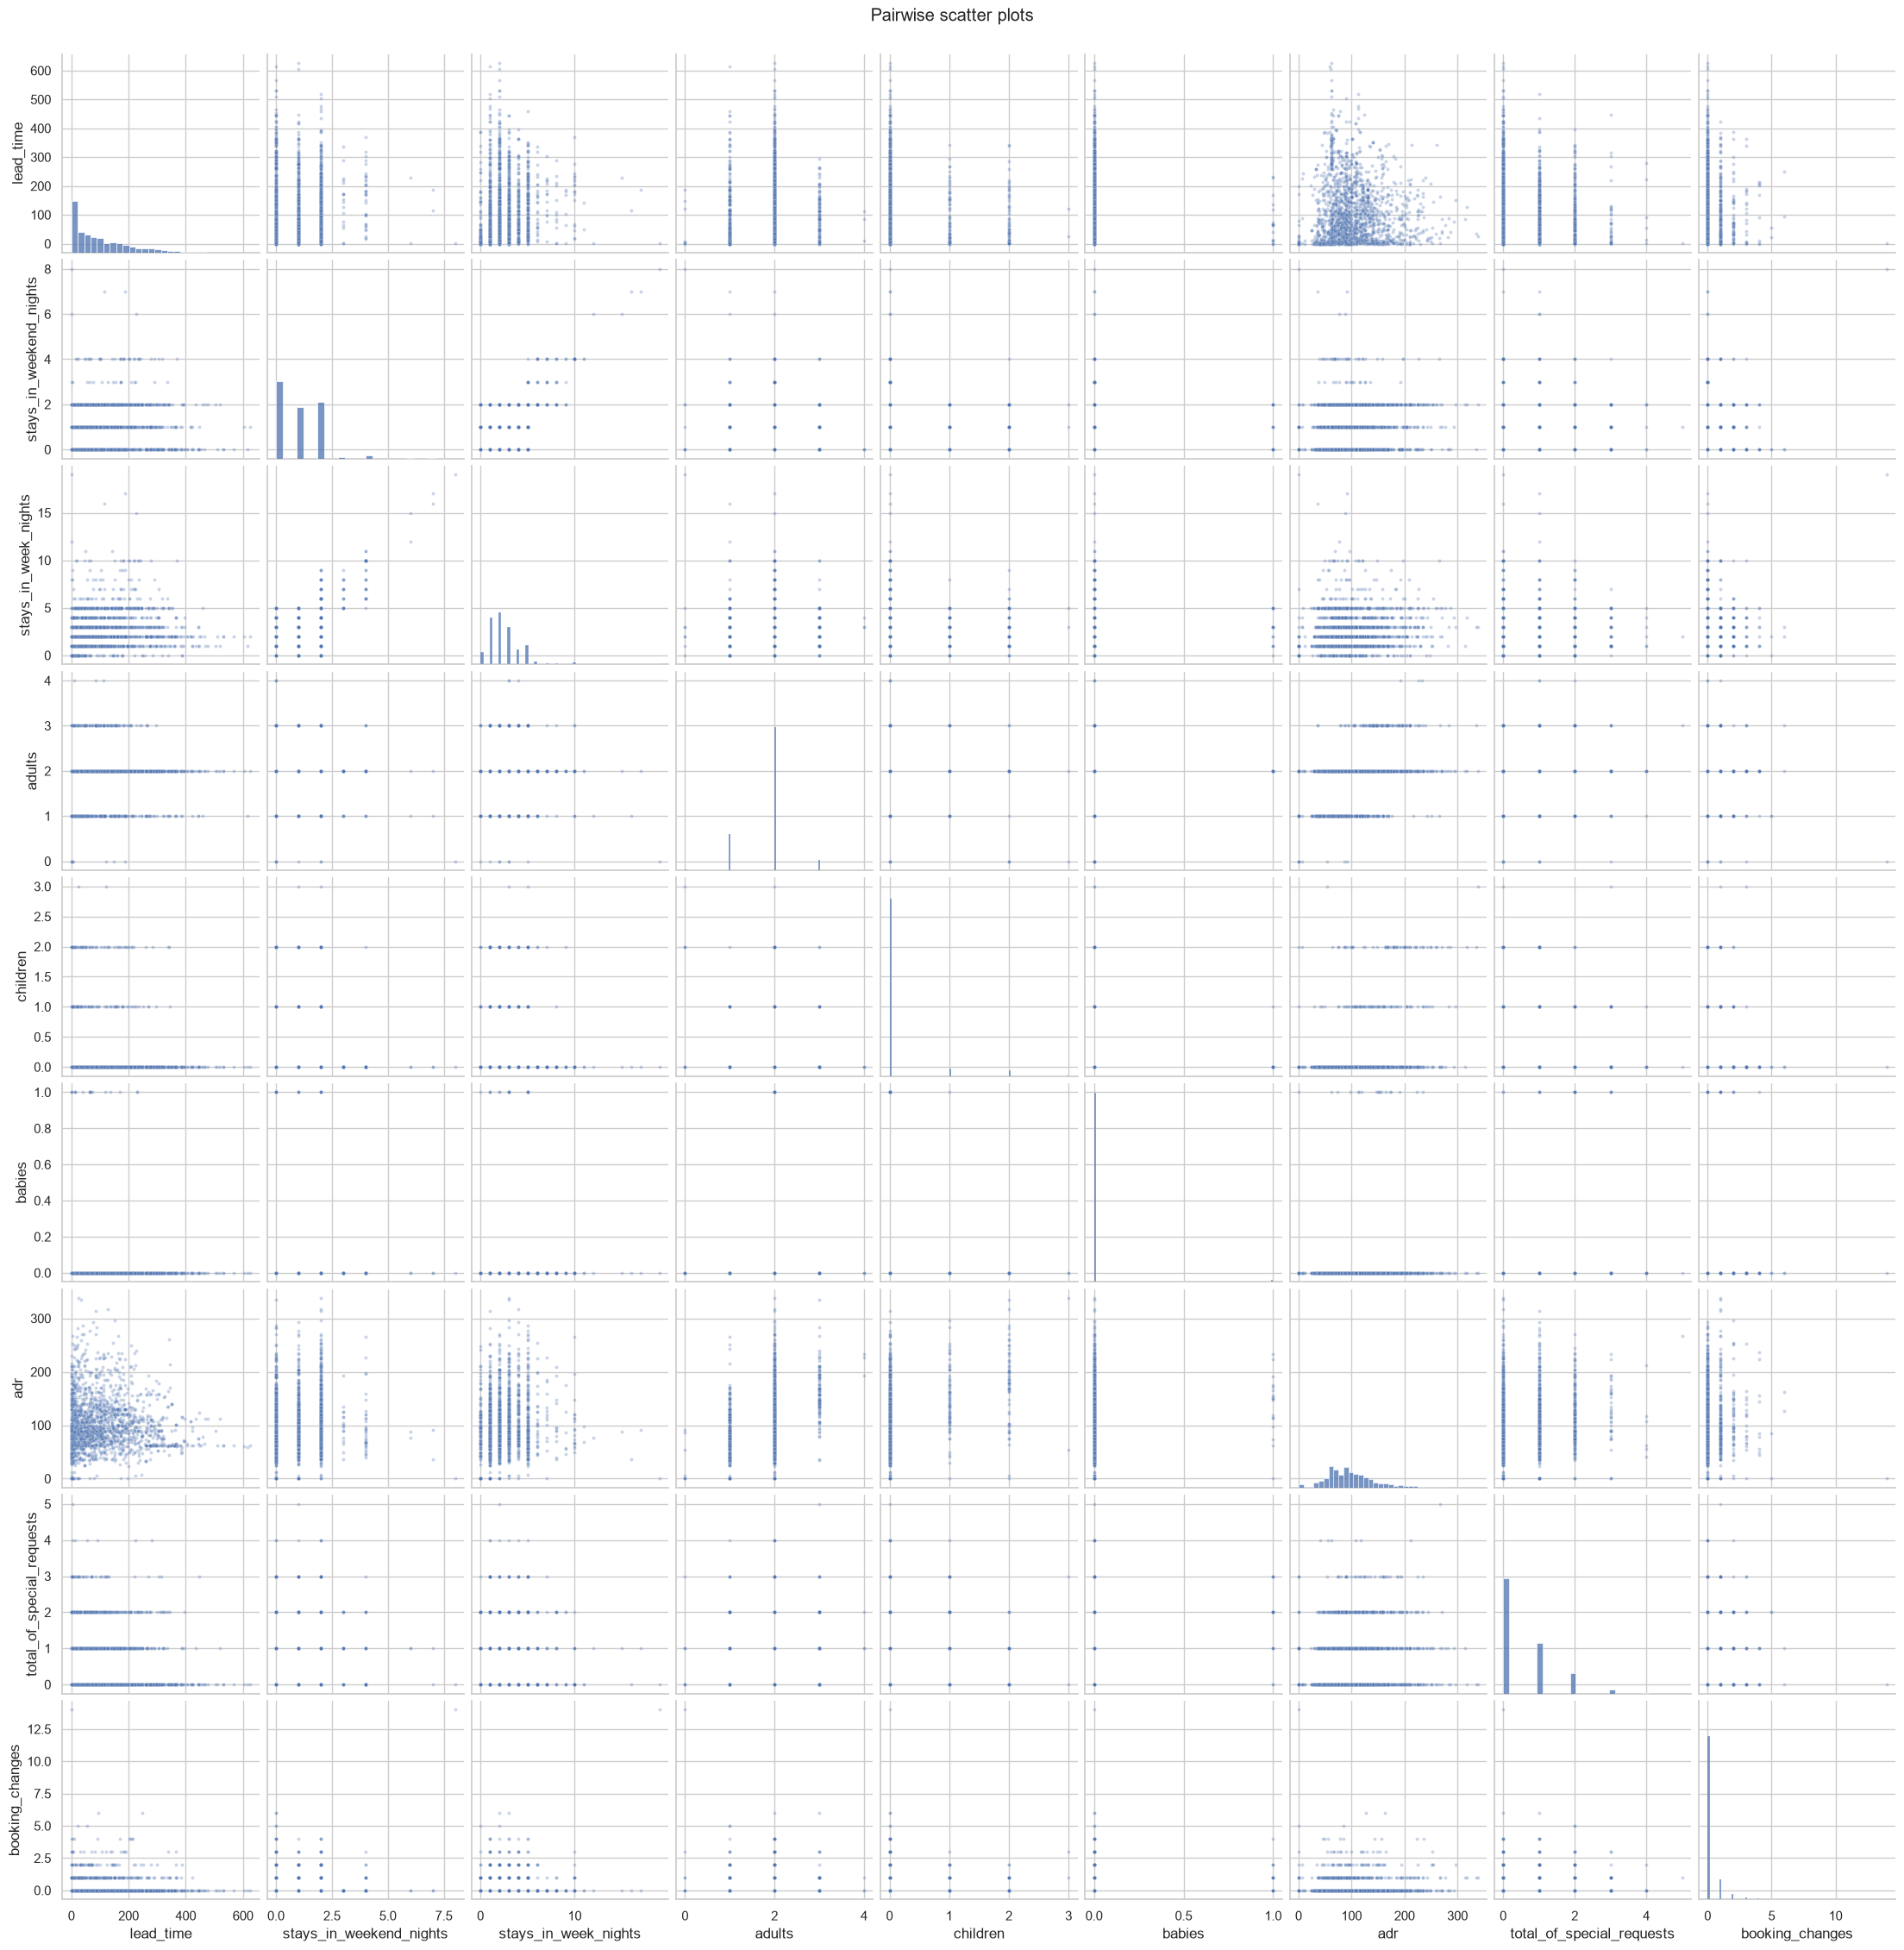

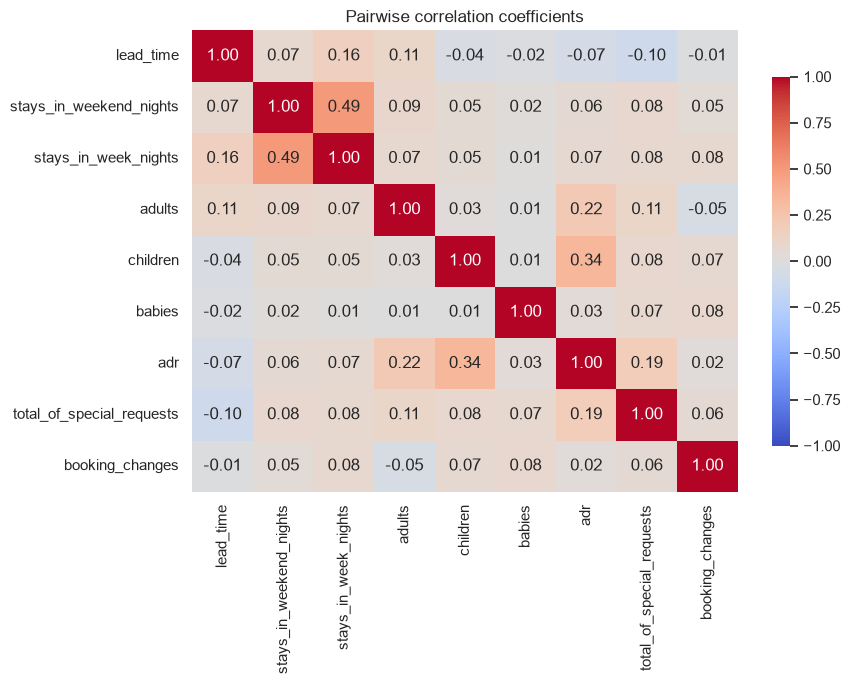

correlation with adr, strongest first:
lead_time                   -0.068320
booking_changes              0.023450
babies                       0.032789
stays_in_weekend_nights      0.058765
stays_in_week_nights         0.069176
total_of_special_requests    0.186108
adults                       0.215382
children                     0.339346
Name: adr, dtype: float64


In [12]:
# Q9 a. Pairwise scatter plots.
# Choose the columns with care. The level of measurement table above
# shows that two columns in this file
# are stored as numbers but are not quantities, and they do not belong here.
pair_cols =pair_cols = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'adr',
    'total_of_special_requests',
    'booking_changes'
]
sns.pairplot(df[pair_cols].dropna().sample(2000, random_state=42),
             plot_kws={'s': 8, 'alpha': 0.3})
plt.suptitle('Pairwise scatter plots', y=1.01)
plt.show()


# Q9 b. Correlation heatmap. The helper returns the matrix as well as drawing
# it, so you can read exact values off it afterwards.
numeric_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
                'adults', 'children', 'babies', 'adr',
                'total_of_special_requests', 'booking_changes']
corr = correlation_heatmap(df, numeric_cols, 'Pairwise correlation coefficients')

print('correlation with adr, strongest first:')
print(corr['adr'].drop('adr').sort_values())                   

# Two questions to answer from this: which columns relate to adr, and is any
# PAIR of features telling you the same thing twice? The second one matters
# for Q11.

**Your conclusions for Q9:**

Children column has the stongest corelation with adr.
stays_in_weekend_nights and stays_in_week_nights have a correlation of 0.49.
babies, booking_changes, and lead_time have very weak correlations with adr and most other numerical features.
There are no pairs with an extremely high correlation that would suggest they are providing almost identical information. However, the two stay-duration columns can be considered as an overlap.
Numerical identifiers such as agent and company were excluded because their values represent categories or IDs, not actual numerical measurements.

## Q10. Carry out the missing value treatment

You set out a plan in Q4 and tested part of it in Q5. Now implement it.

Produce a cleaned frame and show, with evidence, that the treatment did what
you intended. Report how many rows and columns you end up with.

Handle the duplicate rows from Q1 c here as well, and apply any domain
corrections you argued for in Q7.

In [13]:
# Q10. Carry out the plan you wrote in Q4. Work on a copy so df survives.
clean = df.copy()
print('starting shape:', clean.shape)

# Step 1. Duplicates, following your Q1c decision.
clean = clean.copy()
print('after the duplicate decision:', clean.shape)

# Step 2. The column that is too empty to keep.
clean = clean.drop(columns=['company'])       

print('after dropping the unusable column:', clean.shape)

# Step 3. The column where a gap carries meaning. Label it rather than
# imputing it, using what you found in Q5.
clean['agent'] = clean['agent'].fillna('No agent').astype(str)

print("rows labelled 'No agent':", (clean['agent'] == 'No agent').sum())

# Step 4. The column with a small number of gaps.
clean['country'] = clean['country'].fillna('Unknown')
print("rows labelled 'Unknown' country:",
      (clean['country'] == 'Unknown').sum())

# Step 5. The impossible records you identified in Q7.
nights = clean['stays_in_weekend_nights'] + clean['stays_in_week_nights']
before = len(clean)
keep = (clean['adults'] >= 1) & (nights >= 1)

clean = clean[keep]
print('impossible bookings removed:', before - len(clean))

# Evidence that the plan worked.
print()
print('Final shape:', clean.shape)
print('missing values remaining:', clean.isnull().sum().sum())

starting shape: (20000, 24)
after the duplicate decision: (20000, 24)
after dropping the unusable column: (20000, 23)
rows labelled 'No agent': 2775
rows labelled 'Unknown' country: 103
impossible bookings removed: 158

Final shape: (19842, 23)
missing values remaining: 0


**Your conclusions for Q10:**

The data started with a shape of (20000,24). The column company had 18845 missing values so I decided to drop the column (20000,23). The missing values were imputed based on our previous decisions. 158 impossible bookings were removedwhich lead to a shape of (19842,23)

## Q11. A pipeline to predict the average daily rate

Using an sklearn `Pipeline`, bring scaling, encoding and Linear Regression
together to predict `adr`.

Follow these steps.

- Start from the cleaned frame produced in Q10.
- Drop the columns that cannot help: the identifiers and the free text. Say
  which ones and why. Note that `reserved_room_type` and `assigned_room_type`
  are room classes rather than identifiers, so they stay.
- Create a feature `total_nights` by adding the two night columns, then remove
  the originals.
- Encode the categorical variables and scale the numerical ones, both inside
  the pipeline rather than before it.
- Split into training and test sets.
- Report MAE, RMSE and R squared on both the training and the test set, and
  compare them against simply predicting the mean every time.

Then answer two things.

First, which features actually carry the signal, and which turned out to be
decoration? Refer back to your heatmap in Q9.

Second, say what the model is for. Estimating what drove rates across a set of
finished records is a different job from quoting a rate to a guest who is
booking right now, and the second job does not have every column available.
Identify any feature here that could not be known at the moment a booking is
made, decide what to do about it, and report what leaving it out costs.

Note on ordering. The split must happen before anything is fitted. If you
scale the whole frame first then the quantities used to transform the training
data have been computed partly from the test rows, so your reported score is
no longer an honest estimate of performance on data the model has not seen.
Putting the transformations inside the pipeline is what prevents that.

In [15]:
# Q11. Predict adr with a Pipeline.
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

model_df = clean.copy()

# Feature engineering: one length of stay instead of two night columns.
model_df['total_nights'] = model_df['stays_in_weekend_nights']+model_df['stays_in_week_nights']

model_df = model_df.drop(columns=['stays_in_weekend_nights',
                                  'stays_in_week_nights'])

# Drop what cannot generalise to a new booking. Identifiers and a date are not
# features. Room TYPE is a class, not an identifier, so it stays.
columns_to_drop = ['agent', 'reservation_status_date']
model_df = model_df.drop(columns=columns_to_drop)

y = model_df['adr']
X = model_df.drop(columns=['adr'])
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()
print('rows used: %d, numeric: %d, categorical: %d'
      % (len(model_df), len(num_features), len(cat_features)))


# Split FIRST, then let the pipeline fit the transformations on the training
# data only. This ordering is the point of the question.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
])
pipe = Pipeline([
    ('preprocess', preprocess),
    ('model', LinearRegression()),
])
pipe.fit(X_train, y_train)


def report(name, y_true, y_pred):
    return {'set': name,
            'MAE': round(mean_absolute_error(y_true, y_pred), 2),
            'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
            'R2': round(r2_score(y_true, y_pred), 4)}


# Compare against the laziest possible model: always predict the mean.
baseline = np.full(len(y_test), y_train.mean())
results = pd.DataFrame([
    report('train', y_train, pipe.predict(X_train)),
    report('test', y_test, pipe.predict(X_test)),
    report('predict the mean', y_test, baseline),
]).set_index('set')
print(results.to_string())


# Which features carry the signal? Group means are a reasonable first look.
print()
print('mean adr by assigned_room_type:')
print(clean.groupby('assigned_room_type')['adr'].mean().sort_values(ascending=False))
print()
print('mean adr by market_segment:')
print(clean.groupby('market_segment')['adr'].mean().sort_values(ascending=False))

# Then write up: which features carried the signal and which were decoration.
# Refer back to your Q9 heatmap, and to the seasonality you found in Q3.

rows used: 19842, numeric: 9, categorical: 10
                    MAE   RMSE      R2
set                                   
train             21.25  28.93  0.6218
test              21.39  29.16  0.6305
predict the mean  36.38  47.99 -0.0012

mean adr by assigned_room_type:
assigned_room_type
G    171.405967
H    169.843740
F    151.325935
E    118.367677
C    117.271051
K    108.927368
D    106.814024
B     93.689367
A     93.291543
I     68.147027
Name: adr, dtype: float64

mean adr by market_segment:
market_segment
Direct           118.963109
Online TA        117.117420
Aviation         100.364474
Offline TA/TO     88.363360
Groups            79.621592
Corporate         69.140551
Complementary      2.199402
Name: adr, dtype: float64


**Your conclusions for Q11:**

Based on the metrics we can say that overall there is no overfitting based on the simmilar values of the errors on train and test data. The mean adr prediction works badly.

assigned_room_type and market_segment are useful to predict the values of the assigned rooms which is a key factor for calculating and predicting adr. In the heatmap we saw that there was a coreation with children column which is not very evident.

## Q12. Scale the numerical columns and look again

Scale the numerical columns with a suitable technique and justify the one
you chose.

Then redraw the common scale box plot from Q8 using the scaled values, so the
two can be compared directly.

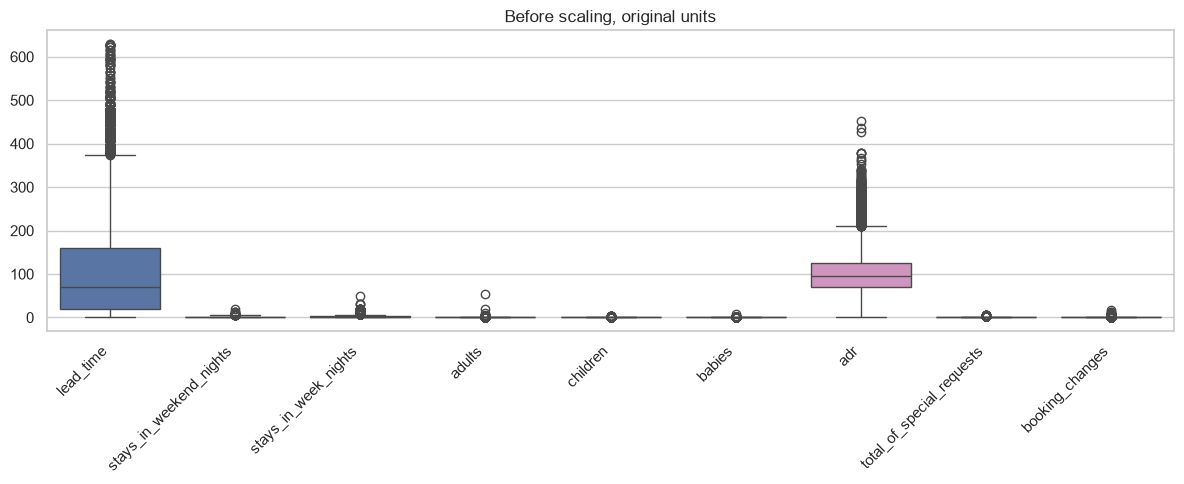

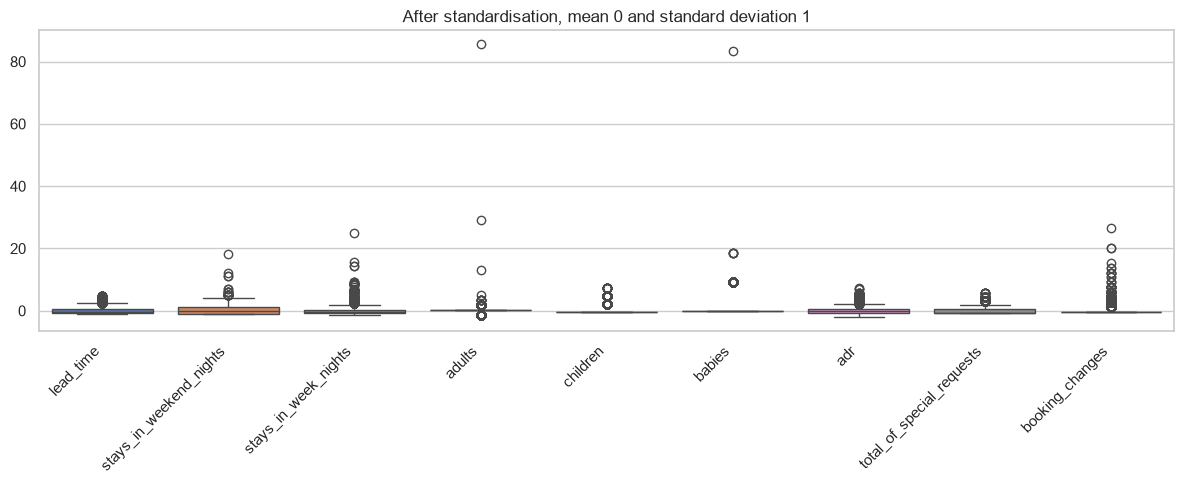

                           mean  std    min     max
lead_time                   0.0  1.0 -0.982   4.896
stays_in_weekend_nights     0.0  1.0 -0.944  18.178
stays_in_week_nights        0.0  1.0 -1.329  25.099
adults                      0.0  1.0 -1.393  85.596
children                    0.0  1.0 -0.258   7.392
babies                     -0.0  1.0 -0.071  83.371
adr                         0.0  1.0 -2.164   7.396
total_of_special_requests   0.0  1.0 -0.714   5.552
booking_changes            -0.0  1.0 -0.342  26.453


In [16]:
# Q12. Scale the numerical columns and look again.
from sklearn.preprocessing import StandardScaler

# the same nine columns Q8 plotted, so the two figures line up
scale_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
              'adults', 'children', 'babies', 'adr',
              'total_of_special_requests', 'booking_changes']

scaled = clean.copy()
scaler = StandardScaler()
scaled[scale_cols] = scaler.fit_transform(clean[scale_cols])

# Draw both, so they can be compared directly against Q8.
common_scale_boxplot(clean, scale_cols, 'Before scaling, original units')
common_scale_boxplot(scaled, scale_cols,
                     'After standardisation, mean 0 and standard deviation 1')

print(scaled[scale_cols].agg(['mean', 'std', 'min', 'max']).T.round(3)
      .to_string())

# Justify your choice of technique in markdown. Then look hard at the axis of
# the second plot before concluding that scaling solved the problem. How far
# does it run, and which two columns put it there?

**Your conclusions for Q12:**

We have chosen the standard scaler, it transforms the features so that they have a mean of approximately zero and a standard deviation of one.
The scaling should have fixed the plot but it doesnt seem to be the case mainly because there are outliers which vary heavily from the average values of the column. Scaling helped but not to the expected extent.

## Q13. Compare before and after

Compare the two box plots from Q8 and Q12 and interpret what scaling did
to the distribution, the spread and the apparent outliers.

Then produce correlation heatmaps before and after scaling and compare those
too. Explain what you find, and make sure your explanation accounts for it.

                           before scaling  after scaling
lead_time                             501            501
stays_in_weekend_nights                32             32
stays_in_week_nights                  568            568
adults                               4786           4786
children                             1405           1405
babies                                140            140
adr                                   620            620
total_of_special_requests             488            488
booking_changes                      2979           2979


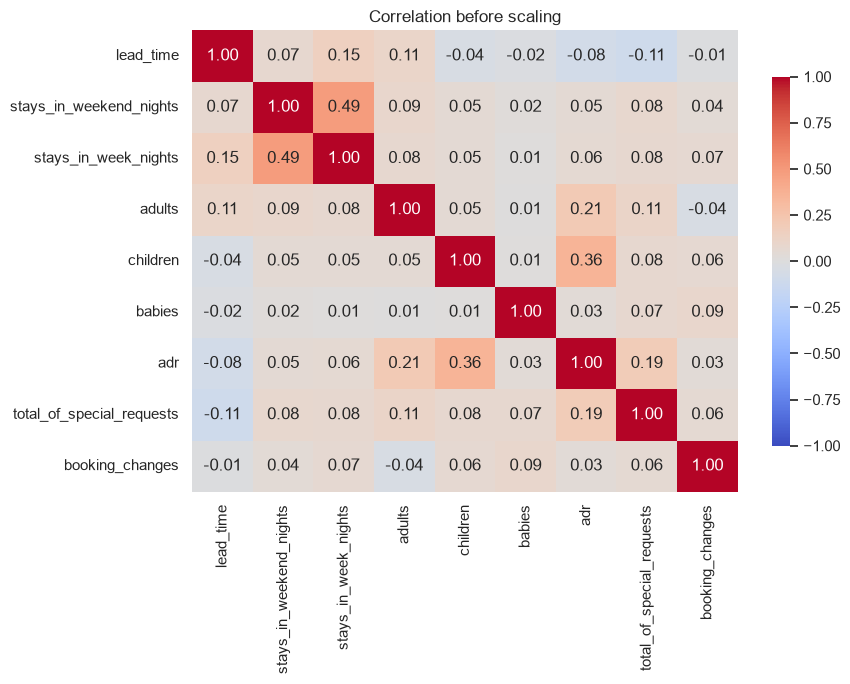

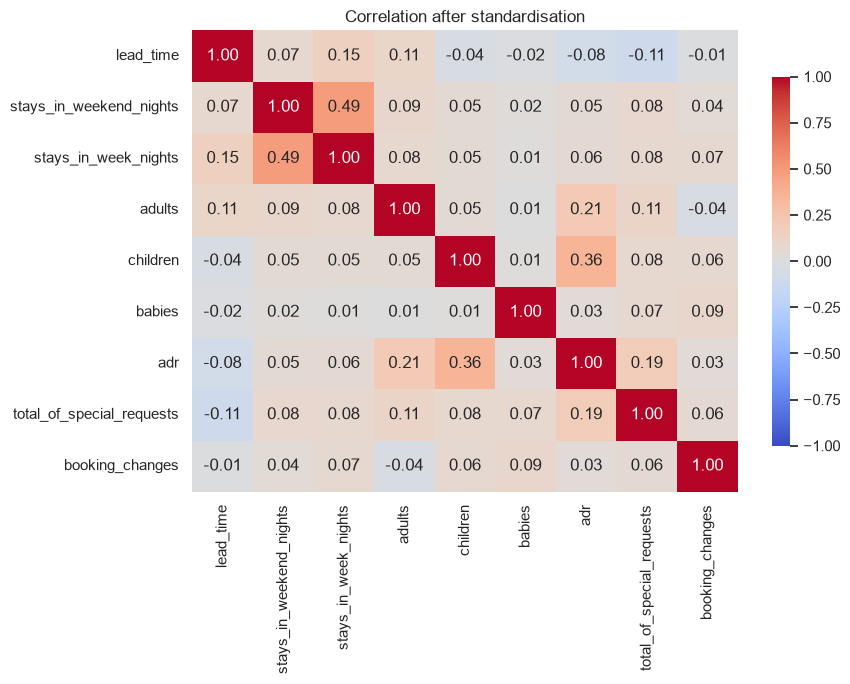

largest difference between the two matrices: 3.22e-15


In [17]:
# Q13. What did scaling actually change?
# Compare the same two things before and after: the outliers, and the
# correlations.

# Outliers: count what the 1.5 x IQR rule flags, on both versions.
def count_flagged(data, columns):
    out = {}
    for col in columns:
        q1, q3 = data[col].quantile(0.25), data[col].quantile(0.75)
        iqr = q3 - q1
        out[col] = int(((data[col] < q1 - 1.5 * iqr)
                        | (data[col] > q3 + 1.5 * iqr)).sum())
    return pd.Series(out)


comparison = pd.DataFrame({
    'before scaling': count_flagged(clean, scale_cols),
    'after scaling': count_flagged(scaled, scale_cols),
})
print(comparison.to_string())

# Correlations: draw both heatmaps and measure the difference between them.
corr_before = correlation_heatmap(clean, scale_cols, 'Correlation before scaling')
corr_after = correlation_heatmap(scaled, scale_cols,
                                 'Correlation after standardisation')
largest_difference = (corr_after - corr_before).abs().max().max()
print('largest difference between the two matrices: %.2e' % largest_difference)

# Then explain BOTH results in markdown. Why can a linear rescaling not change
# which rows are outliers, and why is a correlation coefficient unaffected by
# scaling? The definition of the correlation coefficient answers the second.

**Your conclusions for Q13:**

On comparing the box plots before and after scaling, I see that because of the outliers it is still difficult to make sense of the plots. The outliers are so further apart that the plots shrink to near 0 and nothing can be visualized properly.

We see that scaling doesnt change the number of outliers. It doesnt change the distribution of the data it tries to bring the mean of the data closer to 0 and standard deviation closer to 1.
Since the range of the values has changed but not the distribution we see that the correlation heatmap before and after standardization looks same. Even mathematically calculating it we see the difference between the 2 matrices is too small.